# Case Study 6: Comparative Analysis of Classification Algorithms for Bank Marketing Prediction

**Subject:** Fundamentals of Data Science (22CSC59)  
**Student:** P Hardhik Reddy | **Roll No.:** 160124733192 | **Section:** CSE-3  
**Year/Semester:** 3rd Year, 5th Semester | **Faculty:** S Durga Devi

## Objective
Compare Logistic Regression, Decision Tree, K-Nearest Neighbours (KNN), and Random Forest for predicting term-deposit subscription. All models use the same stratified 80:20 split and preprocessing pipeline. The `duration` field is excluded from primary model predictors because it is not known before a call takes place.

**Dataset:** `data/bank-full.csv`, loaded with semicolon delimiter.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from IPython.display import display

ROOT = Path.cwd()
DATA_PATH = ROOT / "bank-full.csv"
if not DATA_PATH.exists():
    # Allows execution if notebook is launched from the repository root or notebook folder.
    DATA_PATH = Path("data/bank-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset dimensions:", df.shape)
display(df.head(10))

Dataset dimensions: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


## 1. Data understanding and preprocessing

In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Descriptive statistics:")
display(df.describe(include="all").T)
print("Duplicate records:", int(df.duplicated().sum()))
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
print("Unknown category counts:")
display((df == "unknown").sum().sort_values(ascending=False).to_frame("unknown_count"))
print("Target counts:")
display(df["y"].value_counts().rename_axis("outcome").to_frame("customers"))
print("Target percentages:")
display((df["y"].value_counts(normalize=True)*100).round(2).rename_axis("outcome").to_frame("percent"))

Data types:


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Duplicate records: 0
Missing values by column:


...

,unknown_count
poutcome,36959
contact,13020
education,1857
job,288
age,0
default,0
balance,0
housing,0
marital,0
loan,0


Target counts:


,customers
outcome,
no,39922
yes,5289


Target percentages:


,percent
outcome,
no,88.3
yes,11.7


## 2. Exploratory data analysis

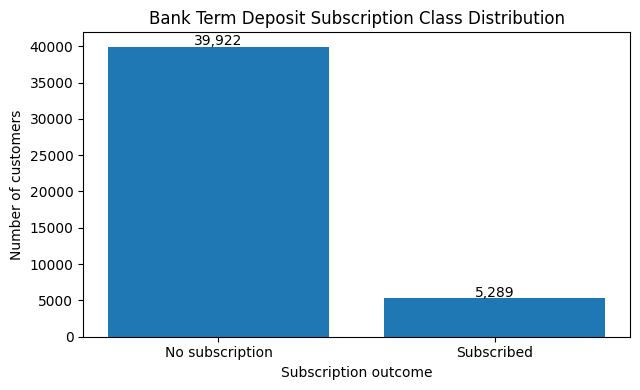

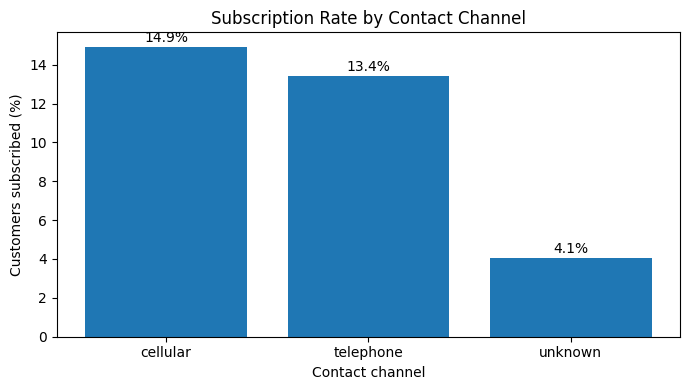

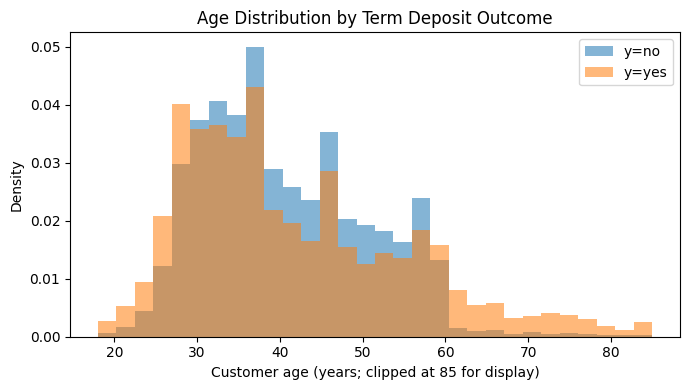

Three observations:
1. 39,922 customers (88.30%) did not subscribe and 5,289 (11.70%) did; the target is imbalanced.
2. Historical subscription rates differ by contact channel; this is association, not evidence of causation.
3. Median age among subscribers is 38; among non-subscribers it is 39. Medians do not imply causation.


In [4]:
target_counts = df["y"].value_counts().reindex(["no", "yes"])
plt.figure(figsize=(6.5,4))
bars = plt.bar(["No subscription", "Subscribed"], target_counts.values)
plt.title("Bank Term Deposit Subscription Class Distribution")
plt.xlabel("Subscription outcome"); plt.ylabel("Number of customers")
for b,v in zip(bars,target_counts.values):
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+200, f"{v:,}", ha="center")
plt.tight_layout(); plt.show()

contact_rates = df.groupby("contact")["y"].apply(lambda s: (s=="yes").mean()*100).sort_values(ascending=False)
plt.figure(figsize=(7,4))
bars = plt.bar(contact_rates.index, contact_rates.values)
plt.title("Subscription Rate by Contact Channel")
plt.xlabel("Contact channel"); plt.ylabel("Customers subscribed (%)")
for b,v in zip(bars,contact_rates.values):
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+.25, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4))
for outcome in ["no","yes"]:
    plt.hist(df.loc[df.y==outcome,"age"].clip(upper=85), bins=30, alpha=.55, density=True, label=f"y={outcome}")
plt.title("Age Distribution by Term Deposit Outcome")
plt.xlabel("Customer age (years; clipped at 85 for display)"); plt.ylabel("Density")
plt.legend(); plt.tight_layout(); plt.show()

print("Three observations:")
print(f"1. {target_counts['no']:,} customers ({target_counts['no']/len(df)*100:.2f}%) did not subscribe and {target_counts['yes']:,} ({target_counts['yes']/len(df)*100:.2f}%) did; the target is imbalanced.")
print("2. Historical subscription rates differ by contact channel; this is association, not evidence of causation.")
print(f"3. Median age among subscribers is {df.loc[df.y=='yes','age'].median():.0f}; among non-subscribers it is {df.loc[df.y=='no','age'].median():.0f}. Medians do not imply causation.")

## 3. Train/test split and classifier development

`duration` is intentionally removed before splitting. Numeric features are median-imputed and standardized; categorical features are imputed with the most frequent value and one-hot encoded. All preprocessing is fitted within each model pipeline to avoid fitting transformations on the test set.

In [5]:
X = df.drop(columns=["y", "duration"])
y = (df["y"] == "yes").astype(int)
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42, stratify=y)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Predictor count before one-hot encoding:", X.shape[1])
print("duration included?", "duration" in X.columns)

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_pipe, numeric_cols), ("cat", categorical_pipe, categorical_cols)])
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, min_samples_leaf=10),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance", n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=160, min_samples_leaf=2, random_state=42, n_jobs=-1)
}
fitted, predictions, probabilities, rows = {}, {}, {}, []
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    fitted[name], predictions[name], probabilities[name] = pipe, pred, prob
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test,pred),
                 "Precision": precision_score(y_test,pred,zero_division=0),
                 "Recall": recall_score(y_test,pred,zero_division=0),
                 "F1-score": f1_score(y_test,pred,zero_division=0),
                 "ROC-AUC": roc_auc_score(y_test,prob)})
results = pd.DataFrame(rows).sort_values(["F1-score","ROC-AUC"], ascending=False).reset_index(drop=True)
display(results.round(3))

Training rows: 36168 | Test rows: 9043
Predictor count before one-hot encoding: 15
duration included? False


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.887,0.537,0.268,0.358,0.719
1,Random Forest,0.896,0.668,0.218,0.329,0.803
2,KNN,0.889,0.576,0.198,0.294,0.714
3,Logistic Regression,0.893,0.663,0.179,0.281,0.772


## 4. Model comparison and evaluation

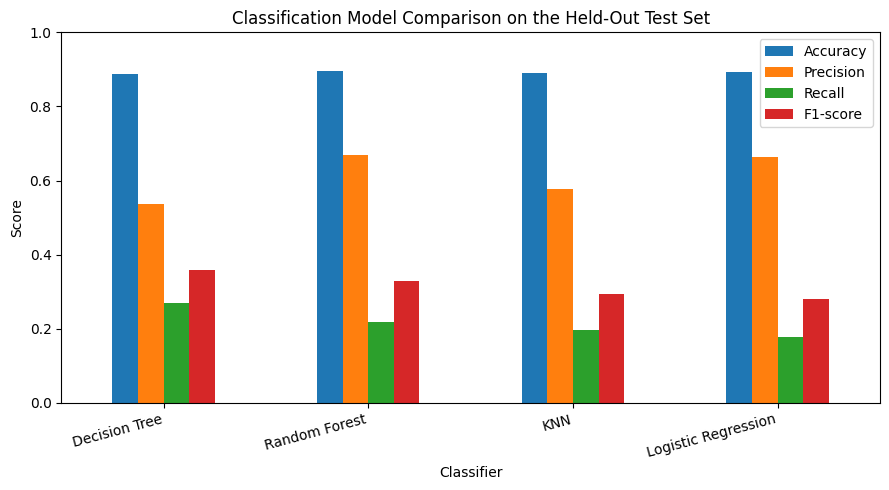

Logistic Regression: confusion matrix (rows = actual [no, yes], columns = predicted [no, yes])


,Predicted no,Predicted yes
Actual no,7889,96
Actual yes,869,189


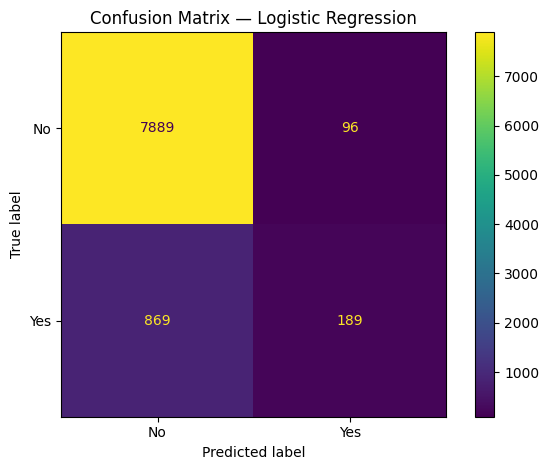

Decision Tree: confusion matrix (rows = actual [no, yes], columns = predicted [no, yes])


,Predicted no,Predicted yes
Actual no,7740,245
Actual yes,774,284


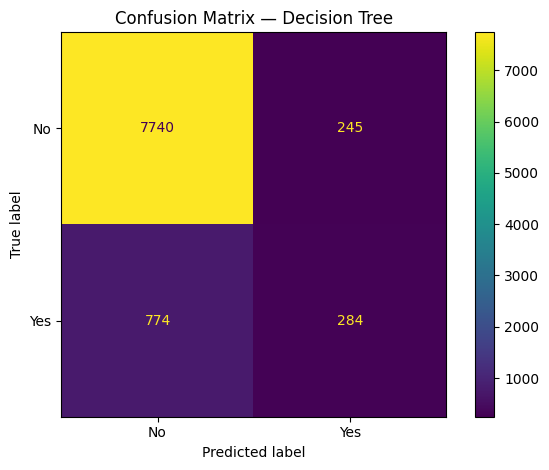

KNN: confusion matrix (rows = actual [no, yes], columns = predicted [no, yes])


,Predicted no,Predicted yes
Actual no,7831,154
Actual yes,849,209


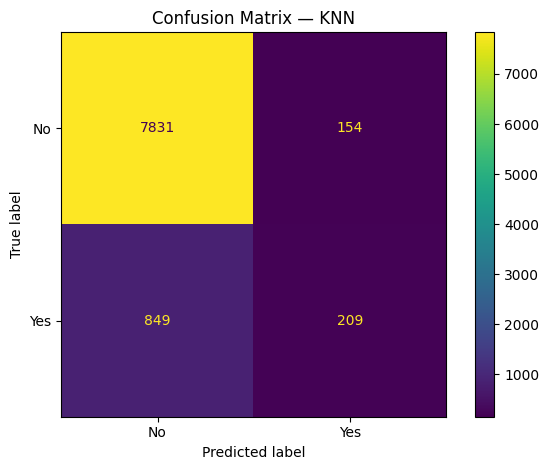

Random Forest: confusion matrix (rows = actual [no, yes], columns = predicted [no, yes])


,Predicted no,Predicted yes
Actual no,7870,115
Actual yes,827,231


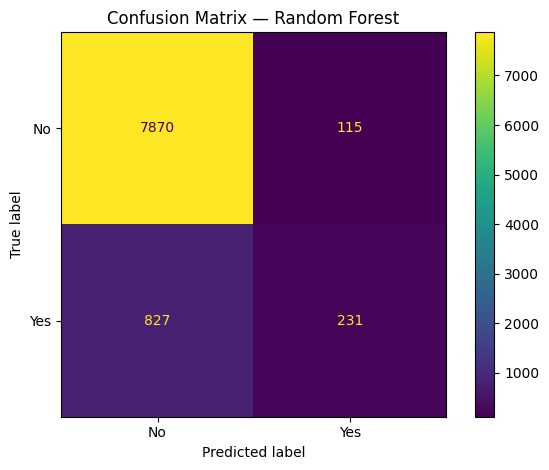

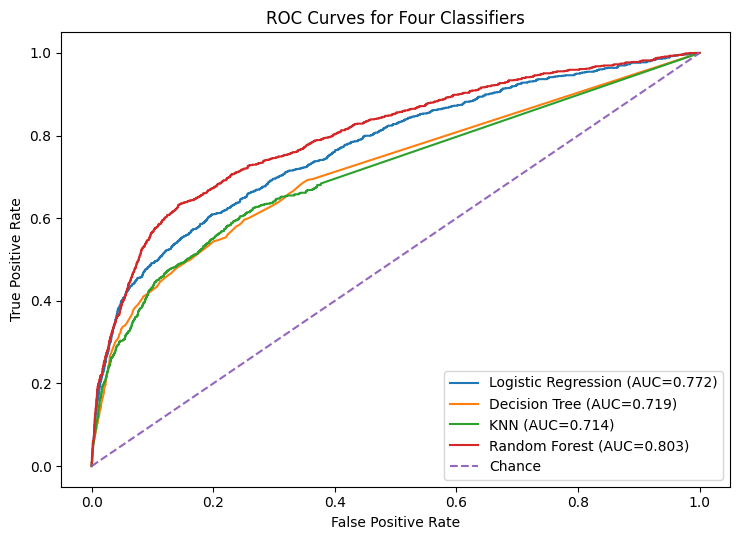

In [6]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = results.set_index("Model")[metric_cols].plot(kind="bar", figsize=(9,5))
ax.set_title("Classification Model Comparison on the Held-Out Test Set")
ax.set_xlabel("Classifier"); ax.set_ylabel("Score"); ax.set_ylim(0,1)
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

for name in models:
    cm = confusion_matrix(y_test, predictions[name])
    print(f"{name}: confusion matrix (rows = actual [no, yes], columns = predicted [no, yes])")
    display(pd.DataFrame(cm, index=["Actual no","Actual yes"], columns=["Predicted no","Predicted yes"]))
    disp = ConfusionMatrixDisplay(cm, display_labels=["No","Yes"])
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout(); plt.show()

plt.figure(figsize=(7.5,5.5))
for name in models:
    fpr,tpr,_ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_test,probabilities[name]):.3f})")
plt.plot([0,1],[0,1],"--",label="Chance")
plt.title("ROC Curves for Four Classifiers")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 5. Findings, model choice and business recommendations

Use the observed comparison table to justify model selection. Accuracy is not sufficient because the subscribed class is a minority. Precision indicates the share of predicted subscribers who actually subscribed; recall indicates the share of actual subscribers identified; F1 balances precision and recall; ROC-AUC evaluates ranking across thresholds.

Business recommendations:
1. Use model scores to prioritize a limited set of customers for contact, and evaluate campaign lift with a controlled pilot.
2. Tune the decision threshold against campaign costs and capacity; monitor precision, recall, F1 and ROC-AUC over time rather than relying on accuracy alone.

Limitations:
1. The data are historical and campaign outcomes may change with time, channel strategy, economic conditions and customer mix.
2. The baseline models use default classification thresholds and limited hyperparameter tuning; class imbalance can suppress recall. Threshold tuning, cross-validation and calibration may improve practical utility.